# Import

In [1]:
%reset -f
import tensorflow as tf
import numpy as np
import copy as cp
import scipy.sparse.linalg as linalg
import matplotlib.pyplot as plt
from time import time
import scipy.optimize
import scipy.stats as stats

gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
  tf.config.experimental.set_memory_growth(gpu, True)

# Paramètres

In [2]:
# Set data type
DTYPE='float32'
tf.keras.backend.set_floatx(DTYPE)

# Set constants
pi = tf.constant(np.pi, dtype=DTYPE)
viscosity = tf.constant(3e-3, dtype=DTYPE)

# Set boundary
tmin = 0.
tmax = 1.
xmin = -1.
xmax = 1.

# Lower bounds
lb = tf.constant([tmin, xmin], dtype=DTYPE)
# Upper bounds
ub = tf.constant([tmax, xmax], dtype=DTYPE)

# Define initial condition
def fun_u_0(x):
    return -tf.sin(pi * x)

# Define boundary condition
def fun_u_b(t, x):
    n = x.shape[0]
    return tf.zeros((n,1), dtype=DTYPE)

## Data generation

In [26]:
def gen_train_data(N_r = 10_000, gaussian=False, sigma = 0.5):

    # Set random seed for reproducible results
    tf.random.set_seed(0)

    # sample collocation points
    t_r = tf.random.uniform((N_r,1), lb[0], ub[0], dtype=DTYPE)
    
    if gaussian: 
        mu = 0.0
        dist = stats.truncnorm( (lb[1] - mu) / sigma, (ub[1] - mu) / sigma, loc=mu, scale=sigma)
        x_r = tf.expand_dims(tf.cast(dist.rvs(N_r), dtype=DTYPE), -1)
    else:
        x_r = tf.random.uniform((N_r,1), lb[1], ub[1], dtype=DTYPE)
        
    X_r = tf.concat([t_r, x_r], axis=1)

    return X_r

def plot_train_data(X_r):

    t_r = X_r[:,0]
    x_r = X_r[:,1]

    fig = plt.figure(figsize=(9,6))
    plt.scatter(t_r, x_r, c='r', marker='.', alpha=0.1)
    plt.xlabel('$t$')
    plt.ylabel('$x$')

    plt.title('Positions of collocation points ');

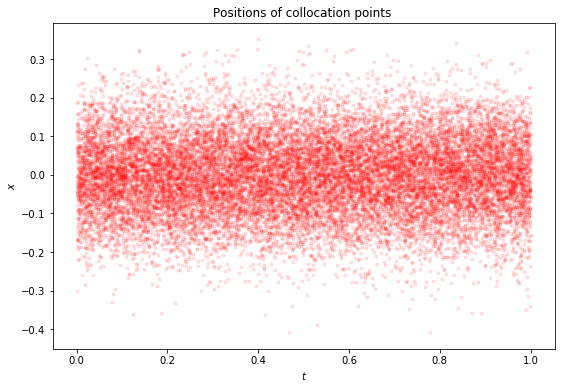

In [28]:
X_r = gen_train_data(20_000, True, .1)
plot_train_data(X_r)

## PINN model

In [5]:
class PhysicsInformedNN(tf.keras.Model):
    """ Set basic architecture of the PINN model."""

    def __init__(self, lb, ub, 
            output_dim=1,
            num_hidden_layers=8, 
            num_neurons_per_layer=20,
            activation='tanh',
            kernel_initializer='glorot_normal',
            **kwargs):
        super().__init__(**kwargs)

        self.num_hidden_layers = num_hidden_layers
        self.output_dim = output_dim
        self.lb = lb
        self.ub = ub
        
        # Define NN architecture
        self.scale = tf.keras.layers.Lambda(
            lambda x: 2.0*(x - lb)/(ub - lb) - 1.0)
        self.hidden = [tf.keras.layers.Dense(num_neurons_per_layer,
                             activation=tf.keras.activations.get(activation),
                             kernel_initializer=kernel_initializer)
                           for _ in range(self.num_hidden_layers)]
        self.out = tf.keras.layers.Dense(output_dim)

    def call_before(self,X):
        """Forward-pass through neural network."""
        
        Z = self.scale(X)
        for i in range(self.num_hidden_layers):
            Z = self.hidden[i](Z)
        Y = self.out(Z)
        
        return Y
        
        
    def call(self, X):
        """Call with imposed IC/BC"""
        
        t = X[:,0:1]
        x = X[:,1:2]
        Y = self.call_before(X)
        
        tanh_t = tf.tanh(t)
        
        return (1-tanh_t)*fun_u_0(x) + (x+1)*(1-x)*tanh_t*Y

In [6]:
class PINNSolver():
    def __init__(self, model, X_r):
        self.model = model
        
        # Store collocation points
        self.t = X_r[:,0:1]
        self.x = X_r[:,1:2]
        
        # Initialize history of losses and global iteration counter
        self.hist = []
        self.iter = 0
        
    def get_r(self):
        
        with tf.GradientTape(persistent=True) as tape:
            # Watch variables representing t and x during this GradientTape
            tape.watch(self.t)
            tape.watch(self.x)
            
            # Compute current values u(t,x)
            u = self.model(tf.stack([self.t[:,0], self.x[:,0]], axis=1))
            u2 = tf.square(u)
            
            u_x = tape.gradient(u, self.x)
            
        u_t = tape.gradient(u, self.t)
        u_xx = tape.gradient(u_x, self.x)
        u2_x = tape.gradient(u2, self.x)

        del tape
        
        return u_t + u2_x/2. - viscosity * u_xx
    
    def loss_fn(self):
        
        # Compute phi_r
        r = self.get_r()
        phi_r = tf.reduce_mean(tf.square(r))

        # Initialize loss
        loss = phi_r
        
        return loss
    
    def get_grad(self):
        with tf.GradientTape(persistent=True) as tape:
            # This tape is for derivatives with
            # respect to trainable variables
            tape.watch(self.model.trainable_variables)
            loss = self.loss_fn()
            
        g = tape.gradient(loss, self.model.trainable_variables)
        del tape
        
        return loss, g
    
    def solve_with_TFoptimizer(self, optimizer, N):
        """This method performs a gradient descent type optimization."""
        
        @tf.function
        def train_step():
            loss, grad_theta = self.get_grad()
            
            # Perform gradient descent step
            optimizer.apply_gradients(zip(grad_theta, self.model.trainable_variables))
            return loss
        
        for i in range(N):
            
            loss = train_step()
            
            self.current_loss = loss.numpy()
            self.callback()

    def solve_with_ScipyOptimizer(self, method='L-BFGS-B'):
        
        def get_weight_tensor():
            """Function to return current variables of the model
            as 1d tensor as well as corresponding shapes as lists."""
            
            weight_list = []
            shape_list = []
            
            # Loop over all variables, i.e. weight matrices, bias vectors and unknown parameters
            for v in self.model.variables:
                shape_list.append(v.shape)
                weight_list.extend(v.numpy().flatten())
                
            weight_list = tf.convert_to_tensor(weight_list)
            return weight_list, shape_list

        x0, shape_list = get_weight_tensor()
        
        def set_weight_tensor(weight_list):
            """Function which sets list of weights
            to variables in the model."""
            idx = 0
            for v in self.model.variables:
                vs = v.shape
                
                # Weight matrices
                if len(vs) == 2:  
                    sw = vs[0]*vs[1]
                    new_val = tf.reshape(weight_list[idx:idx+sw],(vs[0],vs[1]))
                    idx += sw
                
                # Bias vectors
                elif len(vs) == 1:
                    new_val = weight_list[idx:idx+vs[0]]
                    idx += vs[0]
                    
                # Variables (in case of parameter identification setting)
                elif len(vs) == 0:
                    new_val = weight_list[idx]
                    idx += 1
                    
                # Assign variables (Casting necessary since scipy requires float64 type)
                v.assign(tf.cast(new_val, DTYPE))
        
        def get_loss_and_grad(w):
            """Function that provides current loss and gradient
            w.r.t the trainable variables as vector. This is mandatory
            for the LBFGS minimizer from scipy."""
            
            # Update weights in model
            set_weight_tensor(w)
            # Determine value of \phi and gradient w.r.t. \theta at w
            loss, grad = self.get_grad()
            
            # Store current loss for callback function            
            loss = loss.numpy().astype(np.float64)
            self.current_loss = loss            
            
            # Flatten gradient
            grad_flat = []
            for g in grad:
                grad_flat.extend(g.numpy().flatten())
            
            # Gradient list to array
            grad_flat = np.array(grad_flat,dtype=np.float64)
            
            # Return value and gradient of \phi as tuple
            return loss, grad_flat
        
        scipy.optimize.minimize(fun=get_loss_and_grad,
                                       x0=x0,
                                       jac=True,
                                       method=method,
                                       callback=self.callback,
                                       options={'maxiter': 2000,
                                                'maxfun': 50000,
                                                'maxcor': 50,
                                                'maxls': 50,
                                                'ftol': 1.0*np.finfo(float).eps})
        
    def callback(self, xr=None):
        
        if self.iter % 100 == 0:
            print('Iteration {:05d}: loss = {:10.8e}'.format(self.iter,self.current_loss))
        self.hist.append(self.current_loss)
        self.iter+=1
        
    def plot_loss_history(self, ax=None):

        if not ax:
            fig = plt.figure(figsize=(7,5))
            ax = fig.add_subplot(111)

        ax.semilogy(range(len(self.hist)), self.hist,'k-', label='Loss')
        ax.set_xlabel('$Iteration$')
        ax.set_ylabel('Loss')

        return ax

In [7]:
model = PhysicsInformedNN(lb, ub, num_hidden_layers=5, num_neurons_per_layer=30, activation='tanh')
#model.build(input_shape=(None,2))

# Initilize PINN solver
solver = PINNSolver(model, X_r)

In [8]:
t0 = time()
try: 
  lr = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-4,
    decay_steps=1000,
    decay_rate=0.8,
    staircase=True)
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver.solve_with_TFoptimizer(optim, N=5000)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Iteration 00000: loss = 8.60359669e-01
Iteration 00100: loss = 7.84495652e-01
Iteration 00200: loss = 7.38229036e-01
Iteration 00300: loss = 6.31904423e-01
Iteration 00400: loss = 5.52213848e-01
Iteration 00500: loss = 5.23985565e-01
Iteration 00600: loss = 5.13474584e-01
Iteration 00700: loss = 5.04413307e-01
Iteration 00800: loss = 4.93384778e-01
Iteration 00900: loss = 4.77189273e-01
Iteration 01000: loss = 4.52539444e-01
Iteration 01100: loss = 4.26350594e-01
Iteration 01200: loss = 3.95771325e-01
Iteration 01300: loss = 3.63502979e-01
Iteration 01400: loss = 3.24993491e-01
Iteration 01500: loss = 2.78825730e-01
Iteration 01600: loss = 2.33950496e-01
Iteration 01700: loss = 1.95371836e-01
Iteration 01800: loss = 1.67714849e-01
Iteration 01900: loss = 1.48125857e-01
Iteration 02000: loss = 1.31432548e-01
Iteration 02100: loss = 1.19849510e-01
Iteration 02200: loss = 1.10032164e-01
Iteration 02300: loss = 1.00813784e-01
Iteration 02400: loss = 9.11377445e-02
Iteration 02500: loss = 8

In [9]:
t0 = time()
try: 
  solver.solve_with_ScipyOptimizer()
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Iteration 05000: loss = 2.30170395e-02
Iteration 05100: loss = 7.26279523e-03
Iteration 05200: loss = 3.53039848e-03
Iteration 05300: loss = 2.16179457e-03
Iteration 05400: loss = 1.32577994e-03
Iteration 05500: loss = 8.17791268e-04
Iteration 05600: loss = 5.90146228e-04
Iteration 05700: loss = 4.76787187e-04
Iteration 05800: loss = 3.82424565e-04
Iteration 05900: loss = 3.22691107e-04
Iteration 06000: loss = 2.80583132e-04
Iteration 06100: loss = 2.32087259e-04
Iteration 06200: loss = 2.00098279e-04
Iteration 06300: loss = 1.72777291e-04
Iteration 06400: loss = 1.52472610e-04
Iteration 06500: loss = 1.32343717e-04
Iteration 06600: loss = 1.12079833e-04
Iteration 06700: loss = 9.79315519e-05
Iteration 06800: loss = 8.86607158e-05
Iteration 06900: loss = 7.98792753e-05

Training time: 177.92655658721924 seconds


# Vérifications graphiques

In [13]:
from mpl_toolkits.mplot3d import Axes3D

In [16]:
# Set up meshgrid
N = 200
tspace = np.linspace(lb[0], ub[0], N + 1)
xspace = np.linspace(lb[1], ub[1], N + 1)
T, X = np.meshgrid(tspace, xspace)
X_test_grid = np.vstack([T.flatten(),X.flatten()]).T

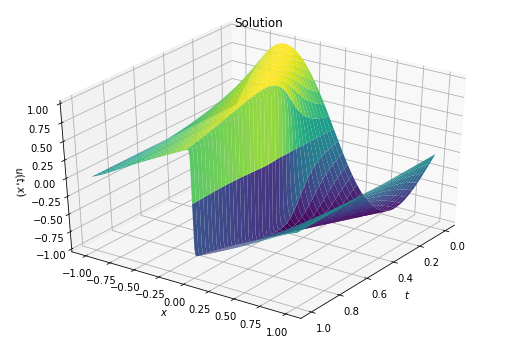

In [17]:
U = model.call(tf.cast(X_test_grid,DTYPE)).numpy().reshape(N+1,N+1)
# Surface plot of u_p
fig = plt.figure(figsize=(9,6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(T, X, U, cmap='viridis');
ax.view_init(35,35)
ax.set_xlabel('$t$')
ax.set_ylabel('$x$')
ax.set_zlabel('$u(t,x)$')
ax.set_title('Solution');

In [31]:
# Set up meshgrid for plotting
N_test = 200
tspace = np.linspace(lb[0], ub[0], N_test + 1)
xspace = np.linspace(lb[1], ub[1], N_test + 1)
T, X = np.meshgrid(tspace, xspace)
X_test = np.vstack([T.flatten(),X.flatten()]).T

In [11]:
def get_residual(model, X_r):
    """fonction qui calcule le résidu"""
    
    # Split t and x to compute partial derivatives
    t, x = X_r[:, 0:1], X_r[:,1:2]
        
    with tf.GradientTape(persistent=True) as tape:
        # Watch variables representing t and x during this GradientTape
        tape.watch(t)
        tape.watch(x)

        # Compute current values u(t,x) and u(t,x)^2
        u = model(tf.stack([t[:,0], x[:,0]], axis=1))
        u2 = tf.square(u)

        u_x = tape.gradient(u, x)

    u_t = tape.gradient(u, t)
    u_xx = tape.gradient(u_x, x)
    u2_x = tape.gradient(u2, x)

    del tape

    return u_t + u2_x/2. - viscosity * u_xx

def get_entropy(model, X_r):
    """fonction qui calcule l'entropie """
    
    with tf.GradientTape(persistent=True) as tape:
        # Split t and x to compute partial derivatives
        t, x = X_r[:, 0:1], X_r[:,1:2]

        # Variables t and x are watched during tape
        # to compute derivatives u_t and u_x
        tape.watch(t)
        tape.watch(x)

        # Determine residual 
        u = model(tf.stack([t[:,0], x[:,0]], axis=1))
        u2 = tf.square(u)
        u3 = u*u2

        # Compute gradient u_x within the GradientTape
        # since we need second derivatives
        u2_x = tape.gradient(u2, x)
            
    eta_t = tape.gradient(u2, t)
    q_x = tape.gradient(u3, x)
    eta_xx = tape.gradient(u2_x, x)

    del tape

    return eta_t/2 +  q_x/3 - viscosity * eta_xx

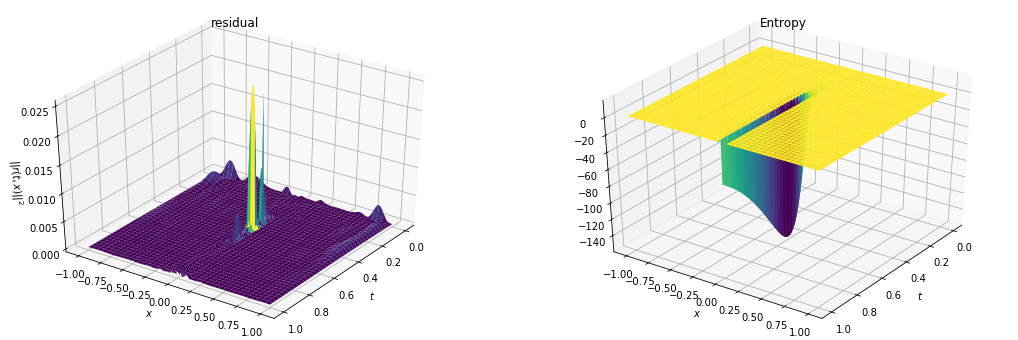

In [32]:
# compute and reshape residual for plotting
Res = get_residual(model, tf.cast(X_test,DTYPE))
R = Res.numpy().reshape(N_test+1,N_test+1)

# compute and reshape entropy
Ent = get_entropy(model,tf.cast(X_test,DTYPE))
S = Ent.numpy().reshape(N_test+1,N_test+1)

# Surface plot of residual
fig = plt.figure(figsize=(18,6))
ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(T, X, np.square(R), cmap='viridis');
ax1.view_init(35,35)
ax1.set_xlabel('$t$')
ax1.set_ylabel('$x$')
ax1.set_zlabel('$||r(t,x)||^2$')
ax1.set_title('residual');

# Surface plot of entropy
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(T, X, S, rcount=50, ccount=50, cmap='viridis');
ax2.view_init(35,35)
ax2.set_xlabel('$t$')
ax2.set_ylabel('$x$')
ax2.set_zlabel('')
ax2.set_title('Entropy');

## comparaison 

Iteration 00000: loss = 7.67438471e-01
Iteration 00100: loss = 5.25830865e-01
Iteration 00200: loss = 5.12529910e-01
Iteration 00300: loss = 4.88738388e-01
Iteration 00400: loss = 4.36595619e-01
Iteration 00500: loss = 3.62869203e-01
Iteration 00600: loss = 3.22224230e-01
Iteration 00700: loss = 3.12833518e-01
Iteration 00800: loss = 3.09238523e-01
Iteration 00900: loss = 3.06536913e-01
Iteration 01000: loss = 3.03839564e-01
Iteration 01100: loss = 3.01418483e-01
Iteration 01200: loss = 2.98571289e-01
Iteration 01300: loss = 2.95096248e-01
Iteration 01400: loss = 2.90733397e-01
Iteration 01500: loss = 2.85251766e-01
Iteration 01600: loss = 2.78857857e-01
Iteration 01700: loss = 2.72583872e-01
Iteration 01800: loss = 2.66842097e-01
Iteration 01900: loss = 2.60381311e-01
Iteration 02000: loss = 2.52351999e-01
Iteration 02100: loss = 2.45513037e-01
Iteration 02200: loss = 2.39178658e-01
Iteration 02300: loss = 2.33184546e-01
Iteration 02400: loss = 2.26892084e-01
Iteration 02500: loss = 2

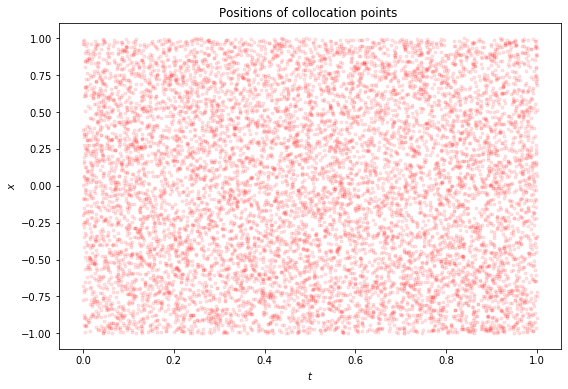

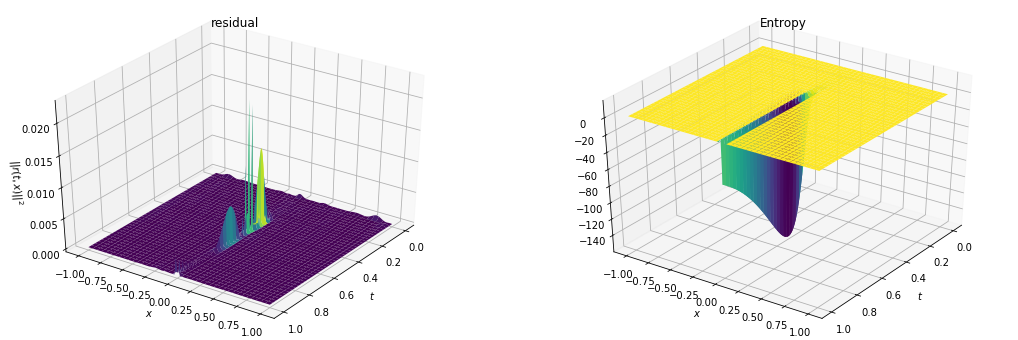

In [33]:
X_r = gen_train_data(10_000, False)
plot_train_data(X_r)

model = PhysicsInformedNN(lb, ub, num_hidden_layers=5, num_neurons_per_layer=30, activation='tanh')

# Initilize PINN solver
solver = PINNSolver(model, X_r)

# training 
t0 = time()
try: 
  lr = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-4,
    decay_steps=1000,
    decay_rate=0.8,
    staircase=True)
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver.solve_with_TFoptimizer(optim, N=5000)
  solver.solve_with_ScipyOptimizer()
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

# compute and reshape residual for plotting
Res = get_residual(model, tf.cast(X_test,DTYPE))
R = Res.numpy().reshape(N_test+1,N_test+1)

# compute and reshape entropy
Ent = get_entropy(model,tf.cast(X_test,DTYPE))
S = Ent.numpy().reshape(N_test+1,N_test+1)

# Surface plot of residual
fig = plt.figure(figsize=(18,6))
ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(T, X, np.square(R), cmap='viridis');
ax1.view_init(35,35)
ax1.set_xlabel('$t$')
ax1.set_ylabel('$x$')
ax1.set_zlabel('$||r(t,x)||^2$')
ax1.set_title('residual');

# Surface plot of entropy
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(T, X, S, rcount=50, ccount=50, cmap='viridis');
ax2.view_init(35,35)
ax2.set_xlabel('$t$')
ax2.set_ylabel('$x$')
ax2.set_zlabel('')
ax2.set_title('Entropy');

Iteration 00000: loss = 8.71652544e-01
Iteration 00100: loss = 7.93033838e-01
Iteration 00200: loss = 7.47738838e-01
Iteration 00300: loss = 6.42866135e-01
Iteration 00400: loss = 5.63763261e-01
Iteration 00500: loss = 5.35003603e-01
Iteration 00600: loss = 5.24335027e-01
Iteration 00700: loss = 5.14936626e-01
Iteration 00800: loss = 5.02892375e-01
Iteration 00900: loss = 4.84151661e-01
Iteration 01000: loss = 4.55255181e-01
Iteration 01100: loss = 4.27318603e-01
Iteration 01200: loss = 3.97760689e-01
Iteration 01300: loss = 3.66703242e-01
Iteration 01400: loss = 3.30416769e-01
Iteration 01500: loss = 2.88148522e-01
Iteration 01600: loss = 2.45489523e-01
Iteration 01700: loss = 2.07615718e-01
Iteration 01800: loss = 1.78511500e-01
Iteration 01900: loss = 1.57861531e-01
Iteration 02000: loss = 1.40637696e-01
Iteration 02100: loss = 1.27921596e-01
Iteration 02200: loss = 1.16993017e-01
Iteration 02300: loss = 1.07191488e-01
Iteration 02400: loss = 9.70362425e-02
Iteration 02500: loss = 8

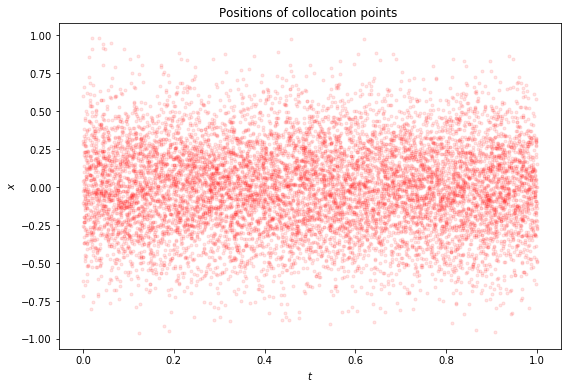

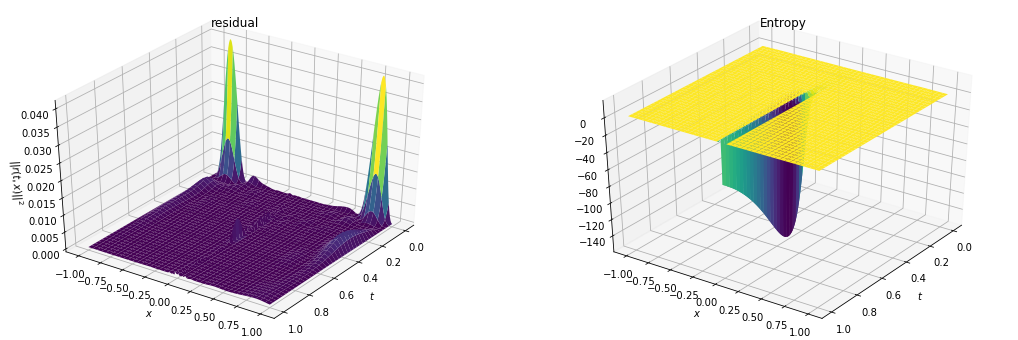

In [34]:
X_r = gen_train_data(10_000, True, 0.3)
plot_train_data(X_r)

model = PhysicsInformedNN(lb, ub, num_hidden_layers=5, num_neurons_per_layer=30, activation='tanh')

# Initilize PINN solver
solver = PINNSolver(model, X_r)

# training 
t0 = time()
try: 
  lr = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-4,
    decay_steps=1000,
    decay_rate=0.8,
    staircase=True)
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver.solve_with_TFoptimizer(optim, N=5000)
  solver.solve_with_ScipyOptimizer()
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

# compute and reshape residual for plotting
Res = get_residual(model, tf.cast(X_test,DTYPE))
R = Res.numpy().reshape(N_test+1,N_test+1)

# compute and reshape entropy
Ent = get_entropy(model,tf.cast(X_test,DTYPE))
S = Ent.numpy().reshape(N_test+1,N_test+1)

# Surface plot of residual
fig = plt.figure(figsize=(18,6))
ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(T, X, np.square(R), cmap='viridis');
ax1.view_init(35,35)
ax1.set_xlabel('$t$')
ax1.set_ylabel('$x$')
ax1.set_zlabel('$||r(t,x)||^2$')
ax1.set_title('residual');

# Surface plot of entropy
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(T, X, S, rcount=50, ccount=50, cmap='viridis');
ax2.view_init(35,35)
ax2.set_xlabel('$t$')
ax2.set_ylabel('$x$')
ax2.set_zlabel('')
ax2.set_title('Entropy');

Iteration 00000: loss = 7.69207239e-01
Iteration 00100: loss = 6.81558788e-01
Iteration 00200: loss = 6.31295025e-01
Iteration 00300: loss = 5.29398143e-01
Iteration 00400: loss = 4.50301319e-01
Iteration 00500: loss = 4.30555522e-01
Iteration 00600: loss = 4.23774302e-01
Iteration 00700: loss = 4.18137252e-01
Iteration 00800: loss = 4.11637783e-01
Iteration 00900: loss = 4.02785361e-01
Iteration 01000: loss = 3.90056551e-01
Iteration 01100: loss = 3.76901180e-01
Iteration 01200: loss = 3.61631006e-01
Iteration 01300: loss = 3.44271630e-01
Iteration 01400: loss = 3.27988684e-01
Iteration 01500: loss = 3.11913610e-01
Iteration 01600: loss = 2.91840583e-01
Iteration 01700: loss = 2.64935315e-01
Iteration 01800: loss = 2.30570808e-01
Iteration 01900: loss = 1.92249998e-01
Iteration 02000: loss = 1.58938259e-01
Iteration 02100: loss = 1.40314922e-01
Iteration 02200: loss = 1.27414301e-01
Iteration 02300: loss = 1.17265970e-01
Iteration 02400: loss = 1.08231932e-01
Iteration 02500: loss = 9

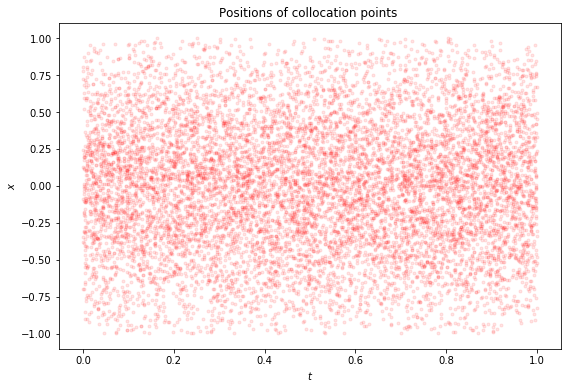

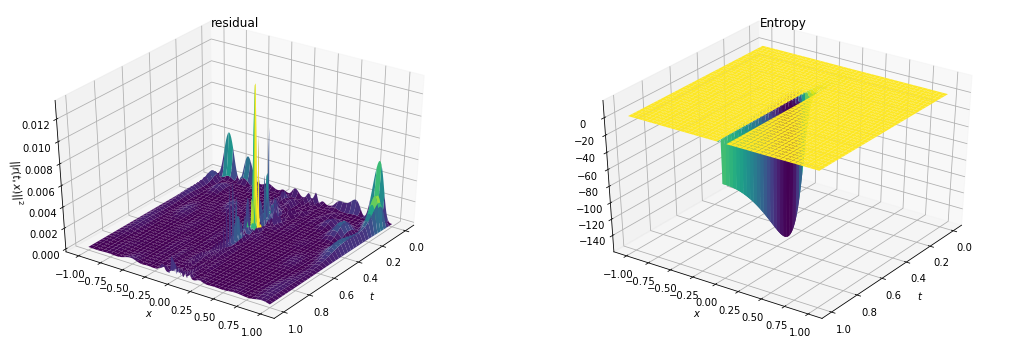

In [35]:
X_r = gen_train_data(10_000, True, 0.5)
plot_train_data(X_r)

model = PhysicsInformedNN(lb, ub, num_hidden_layers=5, num_neurons_per_layer=30, activation='tanh')

# Initilize PINN solver
solver = PINNSolver(model, X_r)

# training 
t0 = time()
try: 
  lr = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-4,
    decay_steps=1000,
    decay_rate=0.8,
    staircase=True)
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver.solve_with_TFoptimizer(optim, N=5000)
  solver.solve_with_ScipyOptimizer()
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

# compute and reshape residual for plotting
Res = get_residual(model, tf.cast(X_test,DTYPE))
R = Res.numpy().reshape(N_test+1,N_test+1)

# compute and reshape entropy
Ent = get_entropy(model,tf.cast(X_test,DTYPE))
S = Ent.numpy().reshape(N_test+1,N_test+1)

# Surface plot of residual
fig = plt.figure(figsize=(18,6))
ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(T, X, np.square(R), cmap='viridis');
ax1.view_init(35,35)
ax1.set_xlabel('$t$')
ax1.set_ylabel('$x$')
ax1.set_zlabel('$||r(t,x)||^2$')
ax1.set_title('residual');

# Surface plot of entropy
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(T, X, S, rcount=50, ccount=50, cmap='viridis');
ax2.view_init(35,35)
ax2.set_xlabel('$t$')
ax2.set_ylabel('$x$')
ax2.set_zlabel('')
ax2.set_title('Entropy');